**Beyond Poverty: Food Access and Mental Distress Across U.S. Neighborhoods, Milestone 2**

Project Group 12

Georgia Hutchinson, Khadijah Olufayo, Jocelyn Shek
TO RUN: pip install pandas pyarrow matplotlib requests ipykernel

In [1]:
import hashlib, json, glob, os, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.labelsize": 11})

## 1. Getting the data

We use three public sources, all on **2010 census tract boundaries**:

| Source | What we take | Link |
|---|---|---|
| USDA ERS **Food Access Research Atlas, 2019 (also known as the Large Retailer Access Map)** | Measures tract-level access to supermarkets, supercenters, and large grocery stores in 2019 (using 2010 census tracts) | https://www.ers.usda.gov/data-products/food-access-research-atlas/download-the-data/ |
| CDC **PLACES, 2021 release**, census-tract data (GIS-friendly format) | Measures health outcomes (at the level of 2010 census tracts) | https://data.cdc.gov/d/mb5y-ytti |
| Census Bureau **American Community Survey 2019 5-year** (API) | Measures income, college attainment, etc over 5 year period (also using 2010 census tract) | https://api.census.gov/data/2019/acs/acs5 |

In [2]:
import datetime
import io
import sys

import requests

PROJECT_DIR = "/content/drive/MyDrive/cs1090a-project"   # CHANGE-ME if your shortcut has another name

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.isdir(PROJECT_DIR):
        raise RuntimeError(
            f"{PROJECT_DIR} not found.\n"
            "In Drive: right-click the shared folder -> Organize -> Add shortcut -> My Drive."
        )
    DATA = f"{PROJECT_DIR}/data"
else:
    DATA = "data"

RAW = Path(DATA) / "raw"
PROCESSED = Path(DATA) / "processed"
os.makedirs(RAW, exist_ok=True)
os.makedirs(PROCESSED, exist_ok=True)

HEADERS = {"User-Agent": "CS1090A-final-project/2026 (Harvard student project)"}
print("cache folder:", DATA)

cache folder: data


In [3]:
PLACES_URL = "https://data.cdc.gov/api/views/mb5y-ytti/rows.csv?accessType=DOWNLOAD"   # PLACES 2021 release, tract level
USDA_URL = ("https://www.ers.usda.gov/media/5627/2019-large-retailer-access-map-lram-"
            "formerly-known-as-the-food-access-research-atlas-fara-data.zip?v=91164")

ACS_YEAR = 2019                     # 5-year estimates, 2015-2019
ACS_URL = f"https://api.census.gov/data/{ACS_YEAR}/acs/acs5"
ACS_VARS = {
    "B17001_001E": "poverty status determined",
    "B17001_002E": "income below poverty level",
    "B19013_001E": "median household income",
    "B15003_001E": "population 25+",
    "B15003_022E": "bachelor's degree",
    "B15003_023E": "master's degree",
    "B15003_024E": "professional degree",
    "B15003_025E": "doctorate",
    "B23025_003E": "civilian labor force",
    "B23025_005E": "unemployed",
    "B25044_001E": "occupied housing units",
    "B25044_003E": "owner-occupied, no vehicle",
    "B25044_010E": "renter-occupied, no vehicle",
}
# 50 states + DC (FIPS codes 03, 07, 14, 43, 52 are unused)
STATE_FIPS = [f"{i:02d}" for i in range(1, 57) if i not in (3, 7, 14, 43, 52)]

In [4]:
MANIFEST = f"{RAW}/manifest.json"


def looks_real(content, min_bytes, marker):
    """Raise if `content` is not the file we wanted."""
    if len(content) < min_bytes:
        raise ValueError(f"only {len(content):,} bytes; first bytes: {content[:200]!r}")
    if marker not in content[:5000]:
        raise ValueError(f"no {marker!r} near the start; first bytes: {content[:200]!r}")


def record(url, params, path, content):
    """Note where a cached file came from, so everyone can check they have the same bytes."""
    manifest = {}
    if os.path.isfile(MANIFEST):
        with open(MANIFEST, encoding="utf-8") as f:
            manifest = json.load(f)
    manifest[os.path.relpath(path, RAW)] = {
        "url": url,
        "params": {k: v for k, v in (params or {}).items() if k != "key"},   # never save the API key
        "fetched_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"),
        "bytes": len(content),
        "sha256": hashlib.sha256(content).hexdigest(),
    }
    with open(MANIFEST, "w", encoding="utf-8") as f:
        json.dump(manifest, f, indent=1)


def fetch_to_cache(url, path, min_bytes, marker, params=None, quiet=False):
    """Download `url` to `path`, but only if `path` is missing and the response looks right."""
    if os.path.isfile(path):
        if not quiet:
            print(f"cached:  {path} ({os.path.getsize(path) / 1e6:.1f} MB)")
        return path
    r = requests.get(url, params=params, headers=HEADERS, timeout=300)
    r.raise_for_status()
    looks_real(r.content, min_bytes, marker)          # check BEFORE anything is written
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path + ".part", "wb") as f:
        f.write(r.content)
    os.replace(path + ".part", path)                  # the file appears only once it is complete
    record(url, params, path, r.content)
    print(f"fetched: {path} ({len(r.content) / 1e6:.1f} MB)")
    return path

In [5]:
places_file = fetch_to_cache(PLACES_URL, f"{RAW}/places_2021_tract.csv",
                             min_bytes=30_000_000, marker=b"TractFIPS")
usda_file = fetch_to_cache(USDA_URL, f"{RAW}/usda_lram_2019.zip",
                           min_bytes=5_000_000, marker=b"PK\x03\x04")   # every zip starts with PK

cached:  data/raw/places_2021_tract.csv (47.7 MB)
cached:  data/raw/usda_lram_2019.zip (9.1 MB)


The ACS is queried one state at a time, because the API returns tracts per state, for which we use a free Census API key

In [6]:
CENSUS_KEY = os.environ.get("CENSUS_KEY", "cdd1066671ec8f5d7770337fc3cd5dd39861fcb6")   # group's free Census API key

acs_dir = f"{RAW}/acs{ACS_YEAR}"
for st in STATE_FIPS:
    path = f"{acs_dir}/state_{st}.json"
    params = {"get": ",".join(["NAME", *ACS_VARS]), "for": "tract:*", "in": f"state:{st}"}
    if not os.path.isfile(path) and CENSUS_KEY:   # only need the key when this state is not cached yet
        params["key"] = CENSUS_KEY
    fetch_to_cache(ACS_URL, path, min_bytes=5_000, marker=b'[["NAME"', params=params, quiet=True)

acs_paths = glob.glob(f"{acs_dir}/state_*.json")
acs_mb = sum(os.path.getsize(p) for p in acs_paths) / 1e6
print(f"ACS: {len(acs_paths)} state files, {acs_mb:.1f} MB")

ACS: 51 state files, 10.9 MB


**Total data size**

In [7]:
def mb(path):
    return os.path.getsize(path) / 1e6

with zipfile.ZipFile(usda_file) as z:
    usda_csv_mb = max(i.file_size for i in z.infolist() if i.filename.lower().endswith(".csv")) / 1e6

sizes = pd.DataFrame({
    "source": ["CDC PLACES 2021 (CSV)", "USDA LRAM 2019 (zip)", "ACS 2015-2019 (51 JSON files)"],
    "MB on disk": [mb(places_file), mb(usda_file), acs_mb],
}).round(1)
print(sizes.to_string(index=False))
print(f"total downloaded: {sizes['MB on disk'].sum():.1f} MB")
print(f"USDA data CSV once unzipped: {usda_csv_mb:.1f} MB")

# Paths used by the loading cells below
usda_zip = Path(usda_file)
places_csv = Path(places_file)
acs_files = sorted(Path(acs_dir).glob("state_*.json"))

                       source  MB on disk
        CDC PLACES 2021 (CSV)        47.7
         USDA LRAM 2019 (zip)         9.1
ACS 2015-2019 (51 JSON files)        10.9
total downloaded: 67.7 MB
USDA data CSV once unzipped: 47.1 MB


**For the USDA data:** Of the 140+ columns in the original dataset, we keep the tract identifiers, the urban flag, 2010 population and housing, and the *distance-based* access measures. Note that we do not use the "food desert" flags, as they are defined partly by the low-income status of a tract.

In [8]:
usda_cols = ["CensusTract", "Urban", "Pop2010", "OHU2010", "PovertyRate", "MedianFamilyIncome",
             "LA1and10", "LAPOP1_10", "lapop1share", "lapop10share",
             "lahunv1share", "lahunv10share", "TractHUNV"]
with zipfile.ZipFile(usda_zip) as z:
    usda_full_shape = pd.read_csv(z.open("Food Access Research Atlas.csv"), nrows=0).shape[1]
    usda = pd.read_csv(z.open("Food Access Research Atlas.csv"), usecols=usda_cols,
                       dtype={"CensusTract": str})
# Pading tract FIPS codes
usda["GEOID"] = usda.pop("CensusTract").str.zfill(11)
print("USDA:", usda.shape, f"(of {usda_full_shape} columns in the file)")

USDA: (72531, 13) (of 147 columns in the file)


**For the PLACES data:** There is one row per tract with many columns representing health measures. We retain two variables, which are not direct counts but model-based smal-area estimates. For our study, we keep and continue considering `MHLTH_CrudePrev`, the percent of adults reporting 14+ days of poor mental health in the past 30 days ("frequent mental distress"), and `DEPRESSION_CrudePrev`, the percent ever told they have depression.

In [9]:
places = pd.read_csv(places_csv, dtype={"TractFIPS": str},
                     usecols=["StateAbbr", "TractFIPS", "TotalPopulation",
                              "MHLTH_CrudePrev", "DEPRESSION_CrudePrev"])
places = places.rename(columns={"TractFIPS": "GEOID", "TotalPopulation": "places_pop",
                                "MHLTH_CrudePrev": "mental_distress",
                                "DEPRESSION_CrudePrev": "depression"})
places["GEOID"] = places["GEOID"].str.zfill(11)
print("PLACES:", places.shape)

PLACES: (72337, 5)


**ACS:** We keep relevant variables. For the sake of understanding the data for the next section of the notebook, we did some preliminary cleaning in the form of converting negative values into missing ones, as the Census API returns unavailable estimates as large negative numbers.

In [10]:
frames = []
for f in acs_files:
    rows = json.loads(f.read_text())
    frames.append(pd.DataFrame(rows[1:], columns=rows[0]))
acs_raw = pd.concat(frames, ignore_index=True)
acs_raw["GEOID"] = acs_raw["state"] + acs_raw["county"] + acs_raw["tract"]

est = [c for c in acs_raw.columns if c.endswith("E") and c != "NAME"]
acs_raw[est] = acs_raw[est].apply(pd.to_numeric)
print("Negative sentinel values replaced:", int((acs_raw[est] < 0).sum().sum()))
acs_raw[est] = acs_raw[est].where(acs_raw[est] >= 0)

def rate(num, den):
    return (num / den).where(den > 0)

acs = pd.DataFrame({
    "GEOID": acs_raw["GEOID"],
    "acs_poverty_rate": rate(acs_raw.B17001_002E, acs_raw.B17001_001E),            # below poverty / poverty universe
    "acs_median_hh_income": acs_raw.B19013_001E,                                    # dollars
    "acs_pct_bachelors_plus": rate(acs_raw[["B15003_022E", "B15003_023E", "B15003_024E", "B15003_025E"]].sum(axis=1),
                                   acs_raw.B15003_001E),                            # adults 25+ with BA or higher
    "acs_unemployment_rate": rate(acs_raw.B23025_005E, acs_raw.B23025_003E),        # unemployed / civilian labor force
    "acs_pct_no_vehicle": rate(acs_raw.B25044_003E + acs_raw.B25044_010E,
                               acs_raw.B25044_001E),                                # owner + renter households with 0 vehicles
})
print("ACS:", acs.shape)

Negative sentinel values replaced: 1024
ACS: (73056, 6)


### Merge, and check the tract boundaries match

**Staff condition:** USDA uses 2010 tracts, while recent PLACES releases use 2020 tracts. We avoid the mismatch by using the **2021 PLACES release**, which uses 2010 tracts, together with the **2019** ACS, also on 2010 tracts. We confirm this below: PLACES' tract population equals the USDA 2010 census population in *every* merged tract, which could only happen if both files use the same 2010 tracts.

In [11]:
merged = (usda.merge(places, on="GEOID", how="inner", validate="1:1")
              .merge(acs, on="GEOID", how="inner", validate="1:1"))

print("Tracts in USDA / PLACES / ACS:", len(usda), len(places), len(acs))
print("Tracts in all three:          ", len(merged))
dropped = usda[~usda.GEOID.isin(merged.GEOID)]
print(f"USDA tracts with no match: {len(dropped)} (median 2010 population = {dropped.Pop2010.median():.0f})")

assert (merged["places_pop"] == merged["Pop2010"]).all()
print("PLACES population == USDA 2010 population in every tract -> boundaries match")

Tracts in USDA / PLACES / ACS: 72531 72337 73056
Tracts in all three:           72335


USDA tracts with no match: 196 (median 2010 population = 8)
PLACES population == USDA 2010 population in every tract -> boundaries match


The 196 USDA tracts that do not match are almost all near-empty (median population 8): water areas, parks and similar tracts that PLACES does not model. Losing them does not matter for our question.

## 2. Understanding the data

Each row represents data related with one 2010 U.S. census tract. Definitionally, each has approximately 4,000 people and can be identified by its 11-digit FIPS code `GEOID` (2-digit state + 3-digit county + 6-digit tract). Meaning of each column is described in the table below:

| Column | Source | Meaning |
|---|---|---|
| `GEOID` | all | 11-digit tract FIPS code |
| `StateAbbr` | PLACES | State postal abbreviation |
| `mental_distress` | PLACES | **Response.** % of adults with ≥14 poor-mental-health days in the past 30 days (model-based) |
| `depression` | PLACES | % of adults ever diagnosed with depression (model-based); a second outcome, never a predictor |
| `places_pop` | PLACES | Tract population used by PLACES (2010 census) |
| `Urban` | USDA | 1 if the tract's centroid is in an urbanized area (≥2,500 people), else 0 |
| `Pop2010`, `OHU2010` | USDA | 2010 census population and occupied housing units |
| `PovertyRate`, `MedianFamilyIncome` | USDA | Poverty rate (%) and median family income from the **2010–2014** ACS |
| `LA1and10` | USDA | 1 if ≥500 people or ≥33% of the tract live >1 mile (urban) / >10 miles (rural) from a supermarket |
| `LAPOP1_10` | USDA | **Number** of people >1 mile (urban) / >10 miles (rural) from a supermarket |
| `lapop1share`, `lapop10share` | USDA | % of population >1 mile / >10 miles from a supermarket |
| `lahunv1share`, `lahunv10share` | USDA | % of housing units with **no vehicle** and >1 / >10 miles from a supermarket |
| `TractHUNV` | USDA | Number of housing units without a vehicle |
| `acs_poverty_rate` | ACS 2019 | Share of people below the federal poverty line |
| `acs_median_hh_income` | ACS 2019 | Median household income ($) |
| `acs_pct_bachelors_plus` | ACS 2019 | Share of adults 25+ with a bachelor's degree or more |
| `acs_unemployment_rate` | ACS 2019 | Unemployed / civilian labor force |
| `acs_pct_no_vehicle` | ACS 2019 | Share of households with no vehicle |

In [12]:
print("Shape of the table:", merged.shape)
print()
print("Data types of the columns:")
print(merged.dtypes.to_string())

Shape of the table: (72335, 22)

Data types of the columns:
Urban                       int64
Pop2010                     int64
OHU2010                     int64
PovertyRate               float64
MedianFamilyIncome        float64
LA1and10                    int64
LAPOP1_10                 float64
lapop1share               float64
lahunv1share              float64
lapop10share              float64
lahunv10share             float64
TractHUNV                 float64
GEOID                         str
StateAbbr                     str
places_pop                  int64
depression                float64
mental_distress           float64
acs_poverty_rate          float64
acs_median_hh_income      float64
acs_pct_bachelors_plus    float64
acs_unemployment_rate     float64
acs_pct_no_vehicle        float64


In [13]:
print("What the table looks like (head):")
merged.head()

What the table looks like (head):


,Urban,Pop2010,OHU2010,PovertyRate,MedianFamilyIncome,LA1and10,LAPOP1_10,lapop1share,lahunv1share,lapop10share,lahunv10share,TractHUNV,GEOID,StateAbbr,places_pop,depression,mental_distress,acs_poverty_rate,acs_median_hh_income,acs_pct_bachelors_plus,acs_unemployment_rate,acs_pct_no_vehicle
0,1,1912,693,11.3,81250.0,1,1896.0,99.19,0.79,NaN,NaN,6.0,01001020100,AL,1912,26.6,17.4,0.166583,60208.0,0.271353,0.028571,0.009873
1,1,2170,743,17.9,49000.0,1,1261.0,58.11,9.00,NaN,NaN,89.0,01001020200,AL,2170,23.9,18.5,0.191340,43958.0,0.171062,0.043651,0.142442
2,1,3373,1256,15.0,62609.0,1,1552.0,46.00,0.00,NaN,NaN,99.0,01001020300,AL,3373,26.7,18.1,0.172512,55345.0,0.184431,0.035196,0.046324
3,1,4386,1722,2.8,70607.0,1,1363.0,31.09,0.46,NaN,NaN,21.0,01001020400,AL,4386,24.7,14.3,0.046416,59663.0,0.348039,0.031987,0.012537
4,1,10766,4082,15.2,96334.0,1,2643.0,24.55,1.35,NaN,NaN,230.0,01001020500,AL,10766,25.1,15.4,0.151626,66108.0,0.423734,0.031174,0.044390


In [14]:
print("Summary statistics of each numerical column:")
summary = merged.describe().T[["count", "mean", "std", "min", "50%", "max"]]
summary.round(3)

Summary statistics of each numerical column:


,count,mean,std,min,50%,max
Urban,72335.0,0.761,0.427,0.0,1.000,1.00
Pop2010,72335.0,4268.192,1946.179,56.0,4018.000,37452.00
OHU2010,72335.0,1613.521,721.860,0.0,1527.000,16043.00
PovertyRate,72332.0,15.205,11.864,0.0,12.000,100.00
MedianFamilyIncome,71779.0,77036.635,37544.102,2499.0,68821.000,250001.00
LA1and10,72335.0,0.380,0.485,0.0,0.000,1.00
LAPOP1_10,42457.0,1615.998,1778.765,0.0,1031.000,27227.00
lapop1share,52380.0,54.024,36.743,0.0,55.120,100.00
lahunv1share,52399.0,2.635,4.046,0.0,1.410,100.00
lapop10share,7742.0,21.681,27.594,0.0,9.425,100.00


From the summary, some considerations arise:

* USDA shares are on a 0–100 scale while ACS rates are 0–1, which we clean up
* `lapop10share` has only ~7,700 values and `lapop1share` ~52,000 out of 72,335, so food access has large gaps (Section 3.3).
* The outcome is missing for about 2,000 tracts (Section 3.2).
* Median incomes are top-coded at \$250,001 and bottom-coded at \$2,499 by the Census Bureau.

## 3. Cleaning and preprocessing

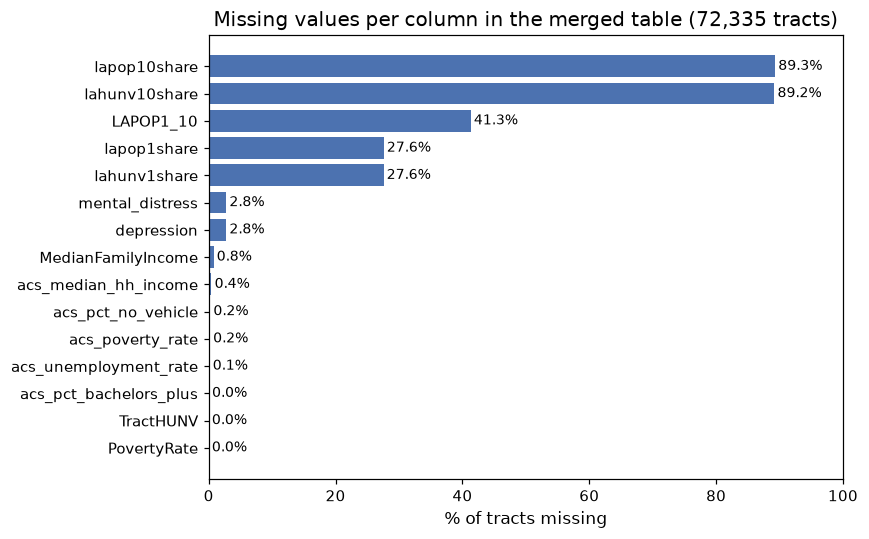

In [15]:
miss = merged.isna().mean().sort_values(ascending=True) * 100
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(miss.index, miss.values, color="#4C72B0")
for i, v in enumerate(miss.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("% of tracts missing")
ax.set_title("Missing values per column in the merged table (72,335 tracts)")
ax.set_xlim(0, 100)
plt.tight_layout(); plt.show()

### 3.1 Identifiers and redundant columns
First, we drop `places_pop` since it is identical to `Pop2010` (checked above). We also add a 2-digit `state_fips` column so we can look for missingness by state and later use state in grouped cross-validation or as a fixed effect.

In [16]:
df = merged.drop(columns=["places_pop"]).copy()
df["state_fips"] = df["GEOID"].str[:2]
assert df["GEOID"].is_unique
df.shape

(72335, 22)

### 3.2 Missing outcome → drop (New Jersey)

In [17]:
no_outcome = df[df["mental_distress"].isna() | df["depression"].isna()]
print(len(no_outcome), "tracts missing an outcome; by state:")
print(no_outcome["StateAbbr"].value_counts().to_string())

1999 tracts missing an outcome; by state:
StateAbbr
NJ    1999


We note that every tract with a missing outcome is in **New Jersey**: the 2021 PLACES release has no estimates for New Jersey, so these values cannot be recovered or sensibly imputed. We drop them, so **our results will cover 49 states + DC, excluding New Jersey**.

In [18]:
df = df.dropna(subset=["mental_distress", "depression"])
print("After dropping New Jersey:", df.shape)

After dropping New Jersey: (70336, 22)


### 3.3 What a blank food-access value means

We saw before that `lapop1share` is blank for ~37% of urban tracts and `lapop10share` for ~57% of rural tracts, but weren't sure what blanks meant, so we tested whether it could mean 1. an unknown value or 2. too small of a value

In [19]:
print("Blank lapop1share, by whether USDA flags the tract as low access (LA1and10):")
print(pd.crosstab(df["LA1and10"], df["lapop1share"].isna(), margins=True,
                  rownames=["LA1and10"], colnames=["lapop1share blank"]))

reported_not_la = df[(df["LA1and10"] == 0) & df["LAPOP1_10"].notna()]
print("\nLAPOP1_10 blank in a flagged low-access tract:", int((df["LA1and10"].eq(1) & df["LAPOP1_10"].isna()).sum()))
print("Non-low-access tracts that DO report a value: share far from a store (urban 1 mi / rural 10 mi)")
print((reported_not_la["LAPOP1_10"] / reported_not_la["Pop2010"] * 100).describe().round(1).to_string())

Blank lapop1share, by whether USDA flags the tract as low access (LA1and10):
lapop1share blank  False   True    All
LA1and10                              
0                  24439  19171  43610
1                  26726      0  26726
All                51165  19171  70336

LAPOP1_10 blank in a flagged low-access tract: 0
Non-low-access tracts that DO report a value: share far from a store (urban 1 mi / rural 10 mi)
count    14653.0
mean         4.6
std          5.4
min          0.0
25%          0.4
50%          2.7
75%          7.0
max         32.8


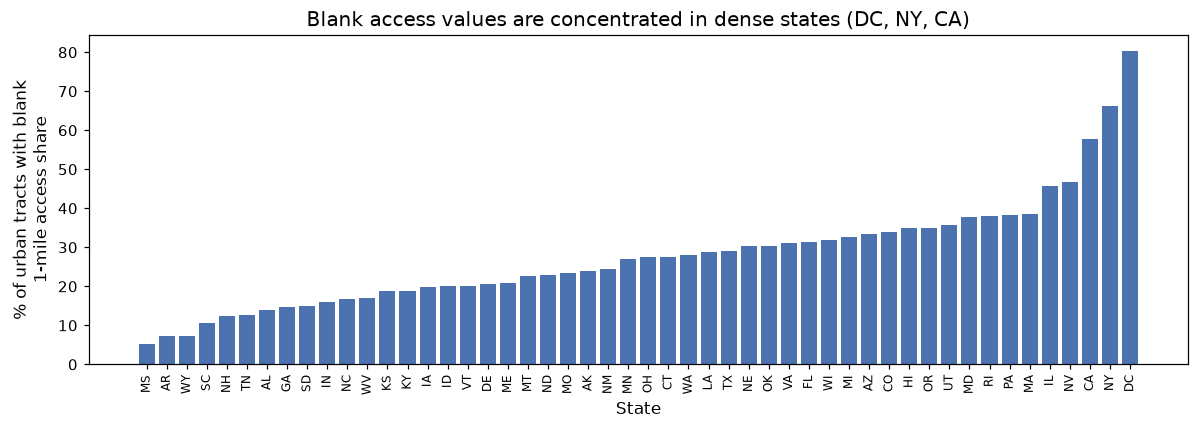

In [20]:
blank_by_state = (df[df["Urban"] == 1].groupby("StateAbbr")["lapop1share"]
                  .apply(lambda s: s.isna().mean() * 100).sort_values())
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(blank_by_state.index, blank_by_state.values, color="#4C72B0")
ax.set_ylabel("% of urban tracts with blank\n1-mile access share")
ax.set_xlabel("State")
ax.set_title("Blank access values are concentrated in dense states (DC, NY, CA)")
plt.xticks(rotation=90, fontsize=8); plt.tight_layout(); plt.show()

We found that blank values in food acess share only occured in tracts that USDA does NOT flag as low-access. In tracts that USDA does not flag as low-access but do report a value for, the share living far from a store is small (median ≈ 3%). Blanks are also most common in the densest states, where almost everyone lives within a mile of a supermarket. So I estimate that blanks represent very few people in that fract living far from a supermarket, below USDA's threshold (<500 people and <33% of the tract), not "unknown". The values are not missing at random, so dropping these tracts would remove most dense urban neighborhoods and bias the sample.

To resolve this, I:
1. Build one access measure that is defined for every tract: `low_access_share` = share of the population beyond **1 mile (urban) or 10 miles (rural)** from a supermarket. That is `lapop1share` for urban tracts and `lapop10share` for rural ones, falling back to `LAPOP1_10 / Pop2010` when the share is blank. This applies the right distance to each tract type and matches the definition in our proposal.
2. Fill blanks with **0** (the true value is small but unknown) and keep a flag `access_suppressed` so the model can absorb any level difference between "0 because suppressed" and a reported value.
3. Do the same for the vehicle measure: `low_access_novehicle_share` = `lahunv1share` (urban) or `lahunv10share` (rural).
4. Keep the binary `LA1and10` flag, which is never missing, as a robustness check.

Note that we keep `lapop1share` / `lapop10share` / `lahunv1share` / `lahunv10share` columns in the final table, rescaled to 0–1 like every other share, with their blanks left as blanks.

In [21]:
urban = df["Urban"] == 1
# Use the share that matches the tract type (USDA reports it as 0-100); if it is blank, fall back to the count.
share = pd.Series(np.where(urban, df["lapop1share"], df["lapop10share"]) / 100, index=df.index)
share = share.fillna(df["LAPOP1_10"] / df["Pop2010"])
df["access_suppressed"] = share.isna().astype(int)
df["low_access_share"] = share.fillna(0).clip(upper=1)

nv = np.where(urban, df["lahunv1share"], df["lahunv10share"]) / 100
df["low_access_novehicle_share"] = pd.Series(nv, index=df.index).fillna(0)

# Sanity check: where reported, the combined measure matches the urban/rural-specific USDA shares
chk_u = df[urban & df["lapop1share"].notna()]
chk_r = df[~urban & df["lapop10share"].notna()]
print("Urban max |diff| vs lapop1share :", (chk_u.low_access_share - chk_u.lapop1share / 100).abs().max().round(4))
print("Rural max |diff| vs lapop10share:", (chk_r.low_access_share - chk_r.lapop10share / 100).abs().max().round(4))
print("Tracts with suppressed access values:", df["access_suppressed"].sum(),
      f"({df['access_suppressed'].mean():.0%})")

# Keep the raw USDA shares, on the same 0-1 scale as everything else (blanks stay blank)
raw_access = ["lapop1share", "lapop10share", "lahunv1share", "lahunv10share"]
df[raw_access] = df[raw_access] / 100

Urban max |diff| vs lapop1share : 0.0
Rural max |diff| vs lapop10share: 0.0
Tracts with suppressed access values: 28953 (41%)


### 3.4 Two sources for poverty and income, and we keep the ACS 2019 versions
USDA's `PovertyRate` and `MedianFamilyIncome` come from the 2010–2014 ACS. Our own ACS pull is from 2015–2019, which matches the 2019 survey data behind PLACES 2021, and it gives all five socioeconomic controls from a single source and period. The two poverty rates are highly correlated (below), so keeping both would add near-duplicate predictors. Thus, we keep the ACS 2019 versions and drop the USDA ones.

In [22]:
print("corr(USDA PovertyRate, ACS poverty rate):",
      round(df["PovertyRate"].corr(df["acs_poverty_rate"]), 3))
df = df.drop(columns=["PovertyRate", "MedianFamilyIncome", "LAPOP1_10"])

corr(USDA PovertyRate, ACS poverty rate): 0.962


### 3.5 Remaining missing values in the socioeconomic controls

In [23]:
ses = ["acs_poverty_rate", "acs_median_hh_income", "acs_pct_bachelors_plus",
       "acs_unemployment_rate", "acs_pct_no_vehicle"]
any_ses_missing = df[ses].isna().any(axis=1)
print(df[ses].isna().sum().to_string())
print(f"\nRows missing any control: {any_ses_missing.sum()} ({any_ses_missing.mean():.2%})")
print("Median 2010 population, rows with a missing control:", df.loc[any_ses_missing, "Pop2010"].median())
print("Median 2010 population, all rows:                  ", df["Pop2010"].median())

acs_poverty_rate          142
acs_median_hh_income      308
acs_pct_bachelors_plus     22
acs_unemployment_rate      98
acs_pct_no_vehicle        170

Rows missing any control: 309 (0.44%)


Median 2010 population, rows with a missing control: 1829.0
Median 2010 population, all rows:                   4012.0


Missing controls occur mostly in small tracts (where median population about half the overall median), where the Census Bureau cannot publish a reliable estimate. Notably, many of these are dominated by group quarters such as prisons, dorms or military bases. Since they make up under 0.5% of rows, we **drop rows missing any control** instead of imputing, which gives us a complete set of controls to model on. `TractHUNV` (4 blanks) duplicates the information in `acs_pct_no_vehicle`, so we drop that column.

In [ ]:
df = df.dropna(subset=ses).drop(columns=["TractHUNV"])
print("After dropping rows with missing controls:", df.shape)
print("Columns that still have blanks:")
print(df.isna().sum()[lambda s: s > 0].to_string())

After dropping rows with missing controls: (70027, 21)
Columns that still have blanks (only the raw USDA shares, kept on purpose):
lapop1share      19099
lahunv1share     19099
lapop10share     62318
lahunv10share    62318


### 3.6 Unusual values
We look for impossible values and for real but extreme ones.

In [25]:
rate_cols = ["mental_distress", "depression"]
print("Outcomes outside 0–100:", int(((df[rate_cols] < 0) | (df[rate_cols] > 100)).sum().sum()))
share_cols = ["low_access_share", "low_access_novehicle_share"] + [c for c in ses if c != "acs_median_hh_income"]
print("Shares outside 0–1:   ", int(((df[share_cols] < 0) | (df[share_cols] > 1)).sum().sum()))

print("\nTracts with OHU2010 == 0:", int((df["OHU2010"] == 0).sum()))
print("Tracts with unemployment rate == 100%:", int((df["acs_unemployment_rate"] == 1).sum()))
print("Tracts with poverty rate == 100%:", int((df["acs_poverty_rate"] == 1).sum()))
df.loc[(df["acs_unemployment_rate"] == 1) | (df["acs_poverty_rate"] == 1) | (df["OHU2010"] == 0),
       ["GEOID", "StateAbbr", "Pop2010", "OHU2010", "acs_poverty_rate", "acs_unemployment_rate", "mental_distress"]].head(10)

Outcomes outside 0–100: 0
Shares outside 0–1:    0

Tracts with OHU2010 == 0: 0
Tracts with unemployment rate == 100%: 0
Tracts with poverty rate == 100%: 1


,GEOID,StateAbbr,Pop2010,OHU2010,acs_poverty_rate,acs_unemployment_rate,mental_distress
37117,29001951000,MO,2587,74,1.0,0.0,36.3


There are no impossible values: every rate and share is within its valid range. Earlier cleaning steps already removed the tracts with zero households and 100% unemployment, because their ACS controls were missing. However, I note one extreme case which is a Missouri tract with 100% poverty, only 74 households for 2,587 people, and the third-highest mental-distress value in the data. But I think this tract is dominanted by state quarters, meaning it is a real estimate, so we keep that. We add a `small_tract` flag (population < 500 or < 50 occupied housing units) so that in Milestone 3 we can check whether results change when small and group-quarters tracts are excluded. We also observe that the outcome has a long right tail (some tracts above 30%). These are real high-distress neighborhoods, not errors, so they stay.

In [26]:
df["small_tract"] = ((df["Pop2010"] < 500) | (df["OHU2010"] < 50)).astype(int)
print("Small tracts flagged:", df["small_tract"].sum())

Small tracts flagged: 136


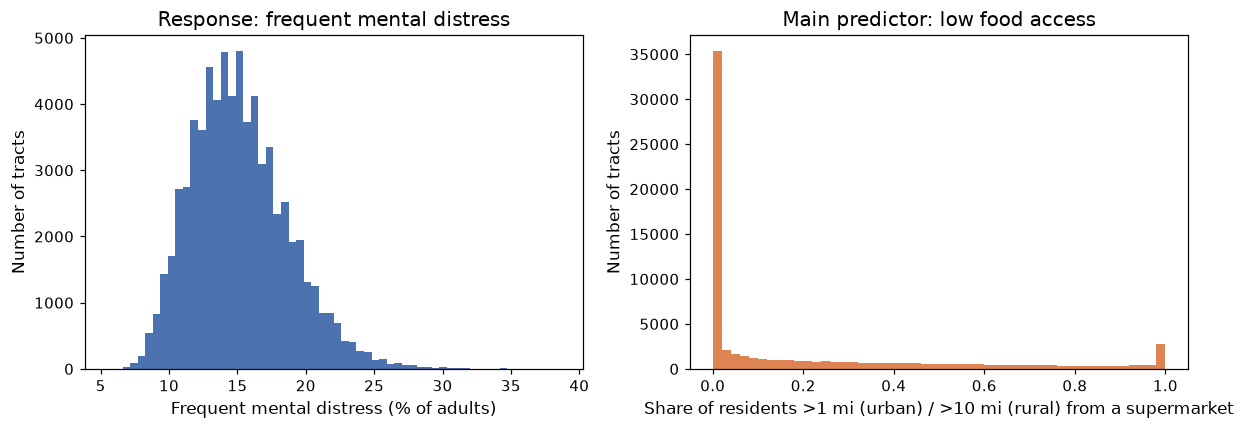

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["mental_distress"], bins=60, color="#4C72B0")
axes[0].set_xlabel("Frequent mental distress (% of adults)")
axes[0].set_ylabel("Number of tracts")
axes[0].set_title("Response: frequent mental distress")
axes[1].hist(df["low_access_share"], bins=50, color="#DD8452")
axes[1].set_xlabel("Share of residents >1 mi (urban) / >10 mi (rural) from a supermarket")
axes[1].set_ylabel("Number of tracts")
axes[1].set_title("Main predictor: low food access")
plt.tight_layout(); plt.show()

We see that the access measure is bimodal, with many tracts near 0 (including the suppressed ones) and many near 1 (suburban and exurban tracts where almost everyone lives more than a mile from a store).

### 3.7 Class balance: group sizes for within-county comparisons
Since we are doing regression, so there is no class imbalance in the response. We are interested in comparing tracts within the same county, so the relevant check is whether countie shave enough tracts, and whether access/distress vary inside counties.

Counties: 3121 | tracts per county: median 6, max 2309
Counties with only 1 tract: 239 (239 tracts, 0.3% of all tracts)
mental_distress      63% of variance is within counties
low_access_share     85% of variance is within counties
acs_poverty_rate     78% of variance is within counties


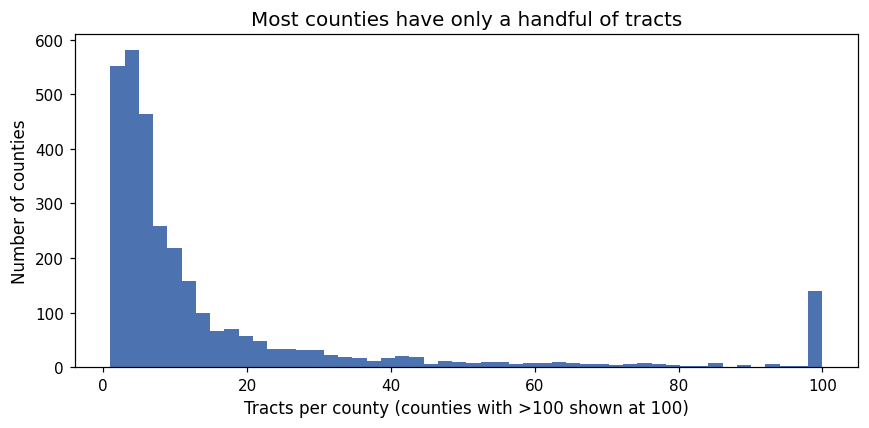

In [65]:
df["county_fips"] = df["GEOID"].str[:5]
n = df.groupby("county_fips").size()
print(f"Counties: {len(n)} | tracts per county: median {n.median():.0f}, max {n.max()}")
print(f"Counties with only 1 tract: {(n == 1).sum()} ({(n == 1).sum()} tracts, {(n == 1).sum() / len(df):.1%} of all tracts)")

def within_share(col):
    """Share of a column's variance that is between tracts in the same county."""
    within = df[col] - df.groupby("county_fips")[col].transform("mean")
    return within.var() / df[col].var()

for col in ["mental_distress", "low_access_share", "acs_poverty_rate"]:
    print(f"{col:20s} {within_share(col):.0%} of variance is within counties")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(n.clip(upper=100), bins=50, color="#4C72B0")
ax.set_xlabel("Tracts per county (counties with >100 shown at 100)")
ax.set_ylabel("Number of counties")
ax.set_title("Most counties have only a handful of tracts")
plt.tight_layout(); plt.show()

There are about 3,100 counties with a median of 6 tracts each. The 239 single-tract counties carry no within-county information, so a fixed-effects model ignores them, yet we keep them because other models still use them. Most of the variation in access (~85%) and in distress (~63%) is within counties, which is good for comparison.

### 3.8 Scale of the features

In [29]:
features = ["low_access_share", "low_access_novehicle_share", "LA1and10",
            "acs_poverty_rate", "acs_median_hh_income", "acs_pct_bachelors_plus",
            "acs_unemployment_rate", "acs_pct_no_vehicle", "Urban", "Pop2010"]
df[features].agg(["min", "max", "mean", "std"]).T.round(3)

,min,max,mean,std
low_access_share,0.0,1.000,0.211,0.307
low_access_novehicle_share,0.0,0.782,0.012,0.032
LA1and10,0.0,1.000,0.380,0.485
acs_poverty_rate,0.0,1.000,0.147,0.114
acs_median_hh_income,2499.0,250001.000,66472.529,32982.048
acs_pct_bachelors_plus,0.0,1.000,0.305,0.192
acs_unemployment_rate,0.0,0.554,0.058,0.043
acs_pct_no_vehicle,0.0,1.000,0.092,0.121
Urban,0.0,1.000,0.756,0.430
Pop2010,62.0,37452.000,4272.729,1945.201


All shares are now on 0–1, but median household income is in dollars (up to 250,001) and population is in thousands.

### 3.9 Information leakage and built-in relationships
* We keep `depression` with the note that it must not be a predictor of `mental_distress`. It is another PLACES estimate from the same survey and the same model, so it would almost restate the outcome. We keep it only as an alternative response.
* PLACES uses county poverty plus tract education as inputs. Some of the poverty and education → distress relationship is therefore built into the response by construction. The model also considers the kind of people that live there (age/race) when estbalishing mental distress, so adding tract age and race composition as controls from the ACS should also explain additional variation.
* We note that access (2019), controls (2015–2019) and the outcome (PLACES 2021 release, 2019 survey data) are all measured before or at the outcome, so no predictor is recorded after the outcome.
* We excluded USDA's `LILA*` food-desert flags and `LowIncomeTracts` because they are defined from income.

### 3.10 Final table

In [30]:
final_cols = ["GEOID", "state_fips", "StateAbbr",
              "mental_distress", "depression",
              "low_access_share", "low_access_novehicle_share", "LA1and10", "access_suppressed",
              "lapop1share", "lapop10share", "lahunv1share", "lahunv10share",
              "acs_poverty_rate", "acs_median_hh_income", "acs_pct_bachelors_plus",
              "acs_unemployment_rate", "acs_pct_no_vehicle",
              "Urban", "Pop2010", "OHU2010", "small_tract"]
clean = df[final_cols].reset_index(drop=True)
out = PROCESSED / "tracts_clean_ms2.parquet"
clean.to_parquet(out, index=False)
print("Clean table:", clean.shape, "->", out)
print("States + DC:", clean["state_fips"].nunique())
clean.head()

Clean table: (70027, 22) -> data/processed/tracts_clean_ms2.parquet
States + DC: 50


,GEOID,state_fips,StateAbbr,mental_distress,depression,low_access_share,low_access_novehicle_share,LA1and10,access_suppressed,lapop1share,lapop10share,lahunv1share,lahunv10share,acs_poverty_rate,acs_median_hh_income,acs_pct_bachelors_plus,acs_unemployment_rate,acs_pct_no_vehicle,Urban,Pop2010,OHU2010,small_tract
0,01001020100,01,AL,17.4,26.6,0.9919,0.0079,1,0,0.9919,NaN,0.0079,NaN,0.166583,60208.0,0.271353,0.028571,0.009873,1,1912,693,0
1,01001020200,01,AL,18.5,23.9,0.5811,0.0900,1,0,0.5811,NaN,0.0900,NaN,0.191340,43958.0,0.171062,0.043651,0.142442,1,2170,743,0
2,01001020300,01,AL,18.1,26.7,0.4600,0.0000,1,0,0.4600,NaN,0.0000,NaN,0.172512,55345.0,0.184431,0.035196,0.046324,1,3373,1256,0
3,01001020400,01,AL,14.3,24.7,0.3109,0.0046,1,0,0.3109,NaN,0.0046,NaN,0.046416,59663.0,0.348039,0.031987,0.012537,1,4386,1722,0
4,01001020500,01,AL,15.4,25.1,0.2455,0.0135,1,0,0.2455,NaN,0.0135,NaN,0.151626,66108.0,0.423734,0.031174,0.044390,1,10766,4082,0


In [31]:
steps = pd.DataFrame([
    ("USDA tracts", len(usda)),
    ("Matched in PLACES and ACS", len(merged)),
    ("Drop New Jersey (no PLACES outcome)", len(merged) - len(no_outcome)),
    ("Drop rows missing an ACS control", len(clean)),
], columns=["step", "tracts"])
steps

,step,tracts
0,USDA tracts,72531
1,Matched in PLACES and ACS,72335
2,Drop New Jersey (no PLACES outcome),70336
3,Drop rows missing an ACS control,70027


## 4. Revised project question

Is reduced access to a grocery store (i.e., living in a “food desert”) associated with worse mental health?
- How does the distance from a grocery store and/or possession of a car impact mental health outcomes?
- Do people in low-income communities with better access to food have lower rates of depression than people in low-income communities with poor access to food?
